# ALP Data Science (B) Group 9


#### Jefferson Wesley Liunardi / 0706022310046 
#### Rio Mulyawan / 0706022310056 
#### Collin Joseph Tjioe / 0706022310053

# Bank Funding Stocks (BBCA) 

## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pmdarima as pm
import statsmodels.api as sm
from datetime import datetime
from sklearn.linear_model import LogisticRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_model import ARIMA
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import adfuller,acf, pacf
from pylab import rcParams
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
import warnings
warnings.filterwarnings('ignore', message='X does not have valid feature names')
import seaborn as sns
from pmdarima.model_selection import train_test_split

## Using ARIMA/SARIMA Method

##  Step 1 : Import Data

In [406]:
# Import data
# Jefferson Data path
bbca_data = pd.read_csv(r"C:\Users\ASUS\Desktop\College\Semester 4\Data Science\Data Historis BBCA.csv")

# Rio Data path
# bbca_data = pd.read_csv(r"/Users/riomulyawan/Documents/Uni/Data Science/Python/ALP/Data Historis BBCA.csv")

## STEP 2: Exploratory analysis of data

In [407]:
# Display basic information about the dataset
print("Dataset Info:")
print(bbca_data.info())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 3200 non-null   object 
 1   Close                3200 non-null   float64
 2   Open                 3200 non-null   float64
 3   High                 3200 non-null   float64
 4   Low                  3200 non-null   float64
 5   Volume               3200 non-null   object 
 6   Percentage Change %  3200 non-null   object 
dtypes: float64(4), object(3)
memory usage: 175.1+ KB
None


In [408]:
# The data are from 2012 to 2025
df = bbca_data
bbca_data = pd.DataFrame(df)

print("\nFirst 5 rows:")
print(bbca_data.head())


First 5 rows:
         Date    Close     Open     High      Low   Volume Percentage Change %
0  26/05/2025 9.550000 9.625000 9.650000 9.525000   26,37M              -1,29%
1  23/05/2025 9.675000 9.775000 9.775000 9.625000   61,19M               0,26%
2  22/05/2025 9.650000 9.800000 9.800000 9.650000  103,11M              -0,52%
3  21/05/2025 9.700000 9.700000 9.725000 9.550000  169,74M               2,37%
4  20/05/2025 9.475000 9.500000 9.675000 9.475000  160,61M              -0,26%


In [409]:
# Check for missing values
print("\nMissing values in each column:")
print(bbca_data.isna().sum())


Missing values in each column:
Date                   0
Close                  0
Open                   0
High                   0
Low                    0
Volume                 0
Percentage Change %    0
dtype: int64


In [410]:
# Convert 'Date' column to datetime format and sort the DataFrame by date
bbca_data['Date'] = pd.to_datetime(bbca_data['Date'], format='%d/%m/%Y')
bbca_data= bbca_data.sort_values(by='Date', ascending=True).reset_index(drop=True)

# Clean the data (remove commas, 'M' for millions, 'K' for thousands, then convert to float)
# Remove '.' from numeric columns
if bbca_data['Open'].dtype != 'int':
    for col in ['Open', 'High', 'Low', 'Close']:
        bbca_data[col] = (bbca_data[col]*1000).astype(int)

# Clean 'Vol.' column: replace abbreviation letter with the correct number and format with commas
if bbca_data['Volume'].dtype == 'object':
    def clean_vol_column(vol):
        vol = str(vol).strip()
        if not vol or vol.lower() in ['nan', 'none']:
            return '0'
        try:
            # Replace commas with dots for decimal conversion
            vol = vol.replace(',', '.')
            if vol.endswith('M'):
                num = float(vol.replace('M', '')) * 1000000
            elif vol.endswith('K'):
                num = float(vol.replace('K', '')) * 1000
            else:
                num = float(vol)
            return f"{int(num):}"
        except Exception:
            return vol

    bbca_data['Volume'] = bbca_data['Volume'].apply(clean_vol_column)
    
# Display the DataFrame
print(bbca_data[['Open', 'High', 'Low', 'Close', 'Volume']].head())

   Open  High   Low  Close    Volume
0  7500  7600  7450   7550   6830000
1  7550  7600  7450   7550  10980000
2  7600  7700  7600   7700  11100000
3  7750  7750  7650   7650   5950000
4  7800  7850  7700   7850  14330000


In [411]:
# Strip leading/trailing whitespaces from column names
bbca_data.columns = bbca_data.columns.str.strip()

# Check the cleaned column names
print(bbca_data.columns)

# Create additional features
bbca_data['daily_return'] = bbca_data['Close'].pct_change()
bbca_data['cumulative_return'] = (1 + bbca_data['daily_return']).cumprod()

bbca_data['rolling_mean_20'] = bbca_data['Close'].rolling(window=20).mean()
bbca_data['rolling_std_20'] = bbca_data['daily_return'].rolling(window=20).std()

Index(['Date', 'Close', 'Open', 'High', 'Low', 'Volume',
       'Percentage Change %'],
      dtype='object')


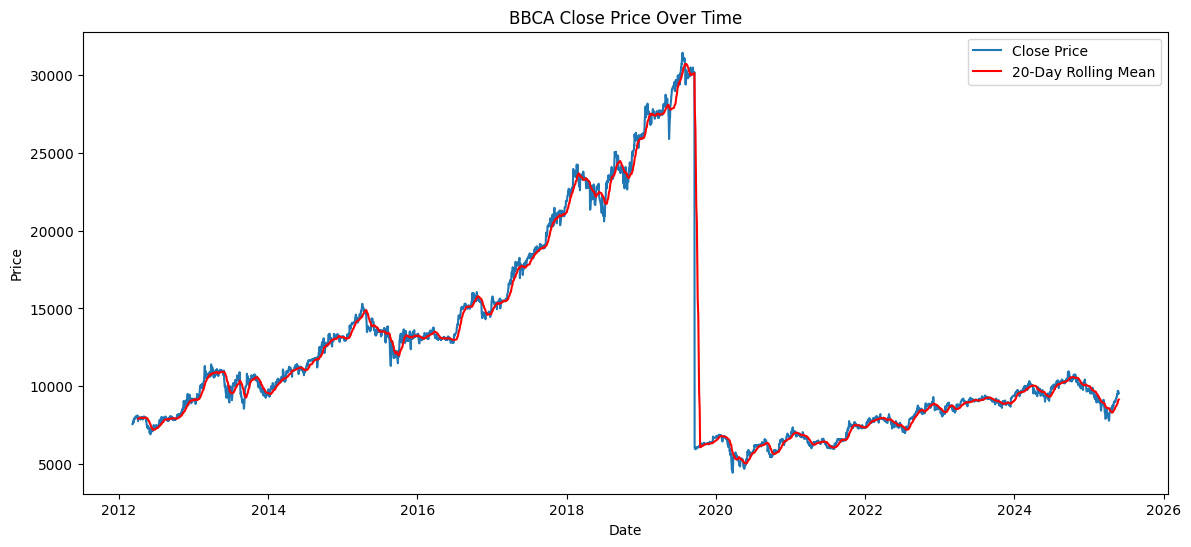

In [412]:
# Line plot of closing price vs. 20-day rolling mean
plt.figure(figsize=(14, 6))
plt.plot(bbca_data['Date'], bbca_data['Close'], label='Close Price')
plt.plot(bbca_data['Date'], bbca_data['rolling_mean_20'], label='20-Day Rolling Mean', linestyle='-', color='red')
plt.title('BBCA Close Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

#### The chart shows BBCA's fluctuating closing prices with a 20-day rolling mean, smoothing out short-term volatility. 
#### A sharp drop in early 2020, likely due to the COVID-19 pandemic, is followed by a gradual recovery.

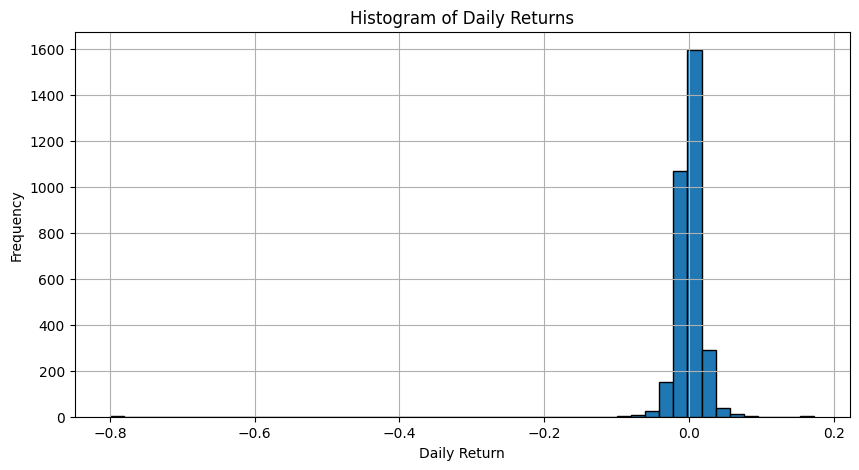

In [413]:
# Daily return histogram
plt.figure(figsize=(10, 5))
bbca_data['daily_return'].hist(bins=50, edgecolor='black')
plt.title('Histogram of Daily Returns')
plt.xlabel('Daily Return')
plt.ylabel('Frequency')
plt.show()

#### The histogram shows the distribution of BBCA's daily returns, with most returns clustered around 0, indicating relative stability. 
#### Extreme daily movements are rare, with only a few outliers in both negative and positive returns, suggesting that larger price changes are less frequent.

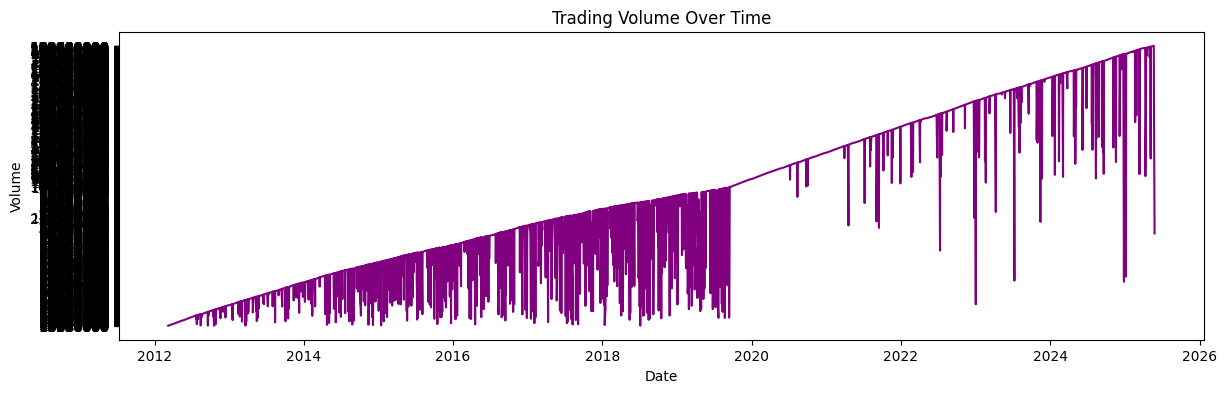

In [414]:
# Volume over time
plt.figure(figsize=(14, 4))
plt.plot(bbca_data['Date'], bbca_data['Volume'], color='purple')
plt.title('Trading Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.show()

#### The chart shows BBCA's trading volume over time, with a steady upward trend from 2012 to 2026, reflecting increased market participation. 
#### Large volume spikes likely indicate significant market events, while the gradual rise points to growing investor interest, particularly during the COVID-19 pandemic.

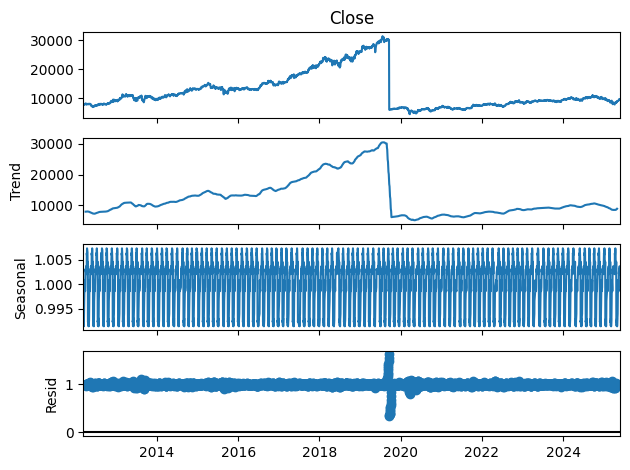

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Pastikan 'Date' sudah dalam format datetime
bbca_data['Date'] = pd.to_datetime(bbca_data['Date'])

# Decomposition of closing price
result = seasonal_decompose(bbca_data.set_index('Date')['Close'], model='multiplicative', period=30)
result.plot()
plt.show()

#### The chart decomposes BBCA's closing price into four components: Close, Trend, Seasonal, and Residual.
#### 1. Close: The raw closing price shows sharp upward movement with a drop in 2020, likely due to the COVID-19 pandemic.
#### 2. Trend: Captures the long-term direction, showing steady increase with a sudden drop in 2020 reflecting market instability.
#### 3. Seasonal: Highlights periodic fluctuations, indicating predictable cycles linked to earnings or economic factors.
#### 4. Residual: Represents noise after removing trend and seasonal effects. The spike in 2020 points to an abnormal market shock.

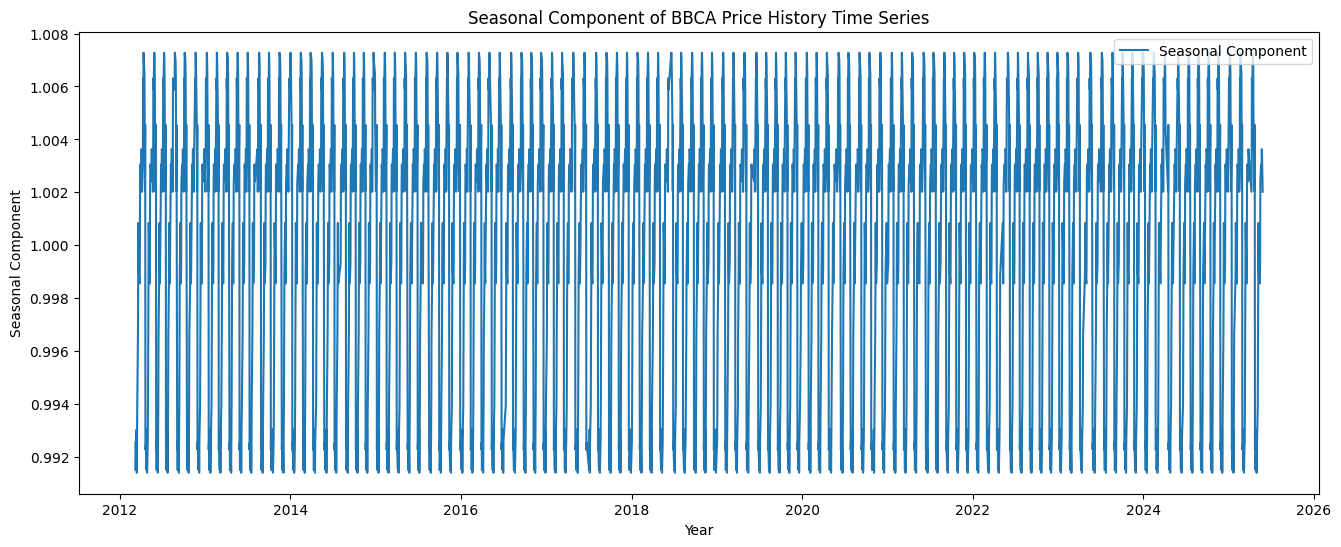

In [418]:
plt.figure(figsize=(16, 6))
plt.plot(result.seasonal, label='Seasonal Component')
plt.title('Seasonal Component of BBCA Price History Time Series')
plt.xlabel('Year')
plt.ylabel('Seasonal Component')
plt.legend()
plt.show()

#### The chart illustrates the seasonal component of BBCA's price history, capturing recurring patterns and cycles in its price movement.
#### The slight oscillations around 1 indicate consistent seasonality, with regular fluctuations linked to factors like quarterly reports, economic cycles, or seasonal events.

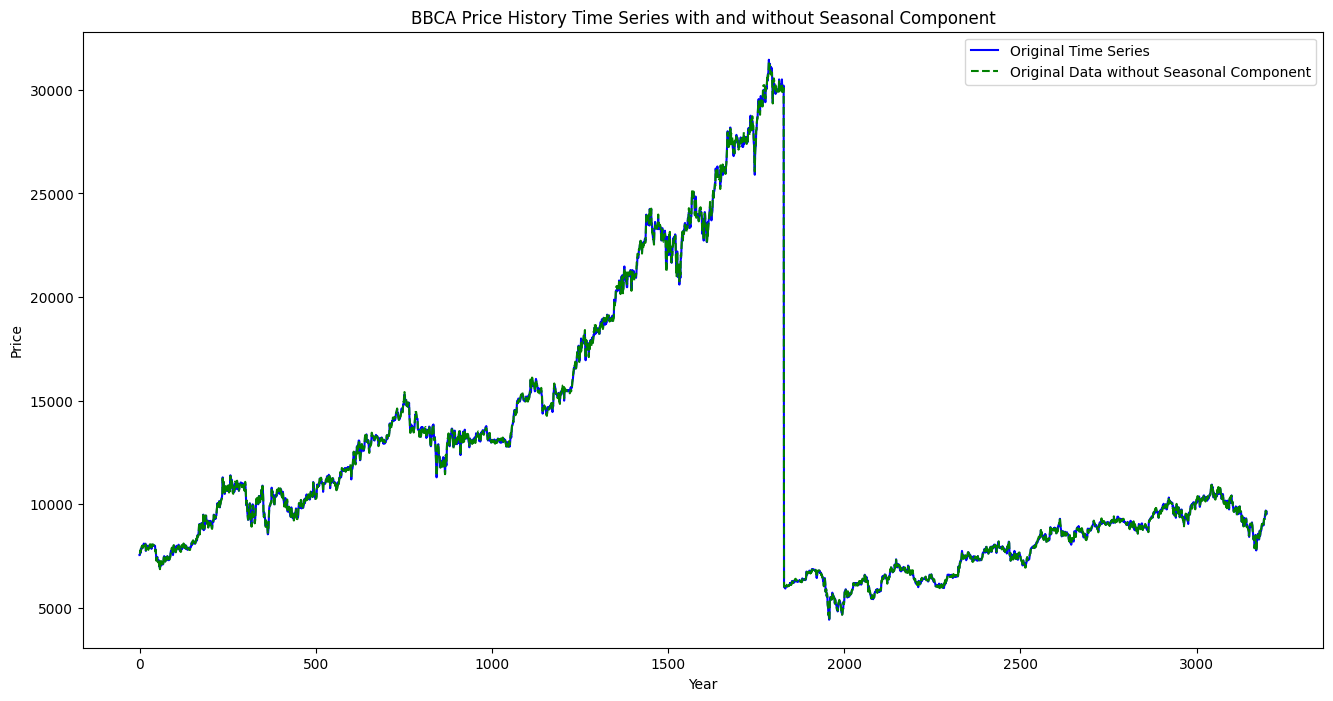

ADF Statistic: -2.1648449899929485
p-value: 0.2192511256893246
The data is not stationary (p-value >= 0.05).


In [419]:
# Plotting the original data and original data without the seasonal component
seasonal = pd.DataFrame(result.seasonal)
seasonal.reset_index(inplace=True)

plt.figure(figsize=(16, 8))
plt.plot(bbca_data['Close'], label='Original Time Series', color='blue')
data_without_seasonal = bbca_data['Close'] / seasonal['seasonal']

plt.plot(data_without_seasonal,
         label='Original Data without Seasonal Component', color='green',linestyle='--')
plt.title('BBCA Price History Time Series with and without Seasonal Component')
plt.xlabel('Year')
plt.ylabel('Price')
plt.legend()
plt.show()

from statsmodels.tsa.stattools import adfuller

#Perform the ADF test on the de - seasonalized data
adf_result = adfuller(data_without_seasonal)

#Extract and display the test statistics and p - value
print('ADF Statistic:', adf_result[0]) 
print('p-value:', adf_result[1])

#Interpreting the results
if adf_result[1] < 0.05 : print("The data is stationary (p-value < 0.05).") 
else: print("The data is not stationary (p-value >= 0.05).")

#### The chart compares BBCA's price history with and without the seasonal component, showing the full price fluctuations (blue) and trend without seasonality (green dashed).
#### The green dashed line highlights the underlying trend, with a noticeable drop around 2020, reflecting an external market shock such as the COVID-19 pandemic.

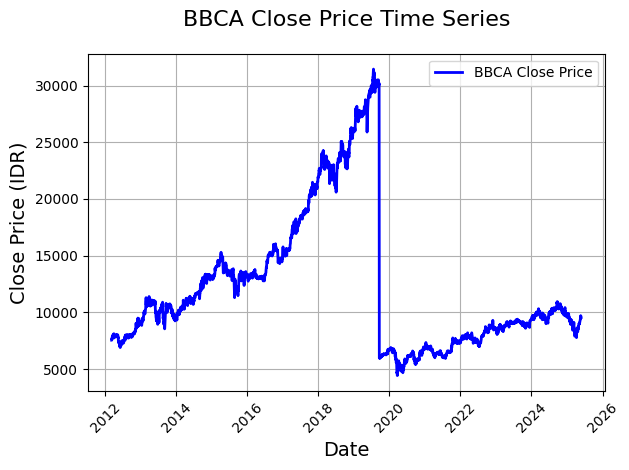

In [ ]:
# Plot the Close price with a line plot
# We will use the 'Close' column for forecasting
plt.plot(bbca_data['Date'], bbca_data['Close'], label='BBCA Close Price', color='blue', linewidth=2)
plt.title('BBCA Close Price Time Series', fontsize=16, pad=20)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Close Price (IDR)', fontsize=14)
plt.grid(True)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()  
plt.show()

#### The chart shows BBCA's closing price over time, with a sharp increase from 2017, followed by a significant drop in early 2020.
#### The drop around 2020 is likely caused by external market factors such as the COVID-19 pandemic, after which the price gradually recovered.

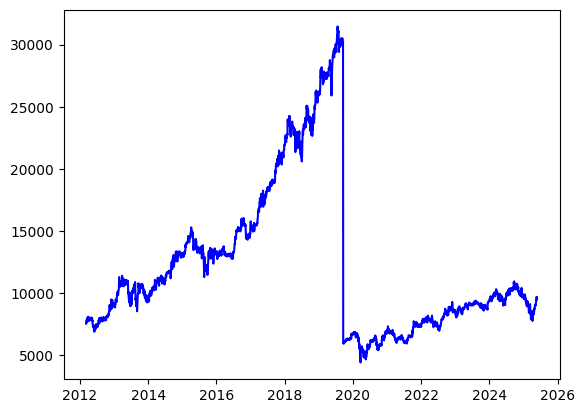

In [ ]:
# Visualize the data with the x, y variables
y = bbca_data['Close'].values
x = bbca_data['Date'].values
plt.plot(x, y, c='blue')
plt.show()

#### Same with above diagram but this chart shows BBCA's closing price over time, with a sharp increase from 2017, followed by a significant drop in early 2020, with x and y variables.
#### The drop around 2020 is likely caused by external market factors such as the COVID-19 pandemic, after which the price gradually recovered.

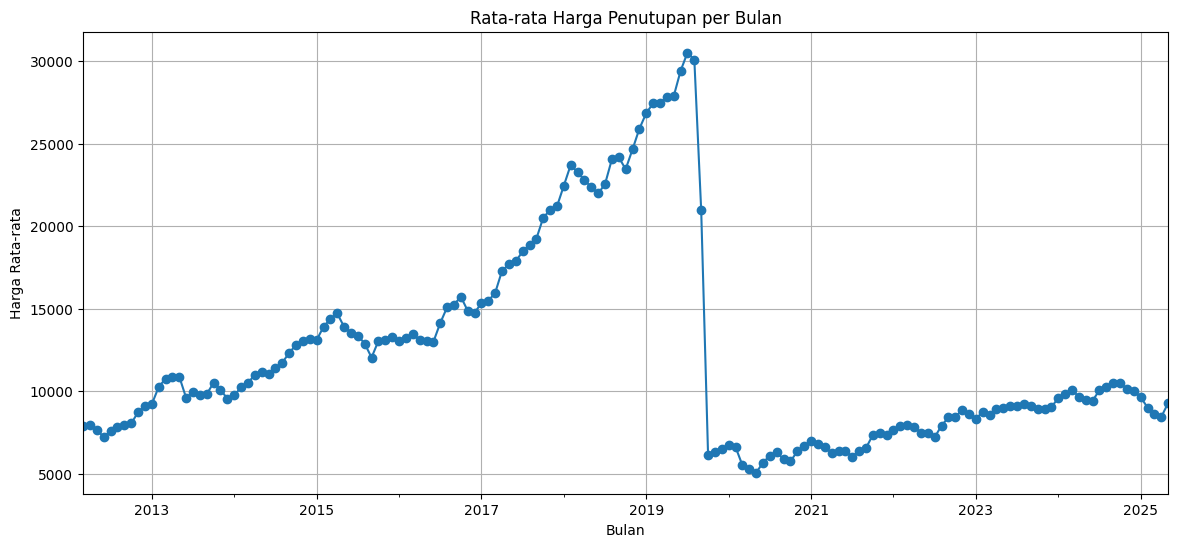

In [420]:
# Monthly average close
bbca_data['month'] = bbca_data['Date'].dt.to_period('M')
monthly_avg = bbca_data.groupby('month')['Close'].mean()

plt.figure(figsize=(14, 6))
monthly_avg.plot(kind='line', marker='o')
plt.title('Rata-rata Harga Penutupan per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Harga Rata-rata')
plt.grid(True)
plt.show()

#### The chart shows BBCA's average monthly closing price over time, with a sharp increase from 2017, followed by a significant drop in early 2020 due to the COVID-19 pandemic.
#### After 2020, the price gradually recovered with some fluctuations, reflecting market recovery and other economic factors on a monthly basis.

In [421]:
monthly_avg
print(bbca_data['daily_return'])

0            NaN
1       0.000000
2       0.019868
3      -0.006494
4       0.026144
          ...   
3195   -0.002632
3196    0.023747
3197   -0.005155
3198    0.002591
3199   -0.012920
Name: daily_return, Length: 3200, dtype: float64


# Bank Funding (BBCA) Using ARIMA/SARIMA Method

## STEP 3 : Split Data

In [424]:
# Check the length of the dataset
train, test = train_test_split(y, train_size=2560)

In [425]:
print(len(train), len(test))

2560 640


In [426]:
y

array([7550, 7550, 7700, ..., 9650, 9675, 9550], shape=(3200,))

In [427]:
y.shape

(3200,)

In [428]:
train

array([ 8775, 23950, 10450, ..., 12950, 15225, 22800], shape=(2560,))

In [429]:
test

array([30500, 25825,  8950, 18675, 30100,  9800,  8875, 10750,  7525,
        8600, 14125,  6480, 11350, 27500, 17325,  9075,  5820,  6025,
       10400, 10050,  9800, 10900, 23800,  6410, 24000,  9200,  6685,
        9200,  9950,  7950,  7500,  7900,  8375, 11025, 10700, 23300,
        8200, 27400,  8850,  8750,  9075, 23925, 25900, 14500, 13150,
        7400, 23175,  7300,  9150, 10375, 23700,  8225,  9600, 13175,
       13575,  6200, 17950, 22000, 23600, 13075,  9250,  7950,  8450,
        6850, 15450, 10175, 11000, 10425, 10150,  7075, 18950, 10200,
        7025, 13725, 15000, 14775, 10450, 13275, 17550, 13550, 12900,
        9250,  9350,  4500,  9850, 24850, 10850,  8200,  7550, 13750,
       14725, 12975, 12900,  7850,  8975,  7450,  6120, 23450, 20800,
        7600,  8500,  8525, 23375,  8150, 13850, 13325,  7175,  6110,
        6465,  7650,  8950, 18500, 20600,  6175,  6410, 18475, 13550,
        8725,  8375, 13025, 10075,  9650,  6200,  5515,  9800,  9575,
       22700,  9325,

## STEP 4: Create ARIMA & SARIMA models based on train data

In [430]:
# arima
arima = pm.auto_arima(train, seasonal=False, error_action='ignore')

c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in

In [431]:
# Model Arima
arima

ARIMA(order=(4, 0, 0), scoring_args={}, suppress_warnings=True)

In [432]:
# sarima
sarima = pm.auto_arima(train, seasonal=True, m=12, error_action='ignore')

c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in

In [433]:
# Model Sarima
sarima

ARIMA(order=(0, 0, 0), scoring_args={}, seasonal_order=(0, 0, 0, 12),
      suppress_warnings=True)

## STEP 5: Do forecasting

In [434]:
forecasts_arima = arima.predict(test.shape[0])

c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [435]:
print(f"Forecast ARIMA length: {len(forecasts_arima)}")
print(f"Forecasts: {forecasts_arima}")

Forecast ARIMA length: 640
Forecasts: [12046.55454591 12237.03100096 12178.10251856 12618.59804566
 12233.64402931 12241.25006637 12231.45871481 12253.23950553
 12239.44657665 12239.88002631 12239.16100529 12240.15438001
 12239.65745289 12239.68494782 12239.64272115 12239.68592251
 12239.66781835 12239.66950424 12239.66728549 12239.66910866
 12239.66843756 12239.66853458 12239.66842563 12239.66850111
 12239.66847565 12239.66848091 12239.6684758  12239.66847889
 12239.6684779  12239.66847817 12239.66847794 12239.66847807
 12239.66847803 12239.66847804 12239.66847803 12239.66847803
 12239.66847803 12239.66847803 12239.66847803 12239.66847803
 12239.66847803 12239.66847803 12239.66847803 12239.66847803
 12239.66847803 12239.66847803 12239.66847803 12239.66847803
 12239.66847803 12239.66847803 12239.66847803 12239.66847803
 12239.66847803 12239.66847803 12239.66847803 12239.66847803
 12239.66847803 12239.66847803 12239.66847803 12239.66847803
 12239.66847803 12239.66847803 12239.66847803 1

In [436]:
forecasts_sarima = sarima.predict(test.shape[0])

c:\Users\ASUS\anaconda3\envs\pmd_env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [437]:
print(f"Forecast SARIMA length: {len(forecasts_sarima)}")
print(f"Forecasts: {forecasts_sarima}")

Forecast SARIMA length: 640
Forecasts: [12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 12240.22578125
 12240.22578125 12240.22578125 12240.22578125 

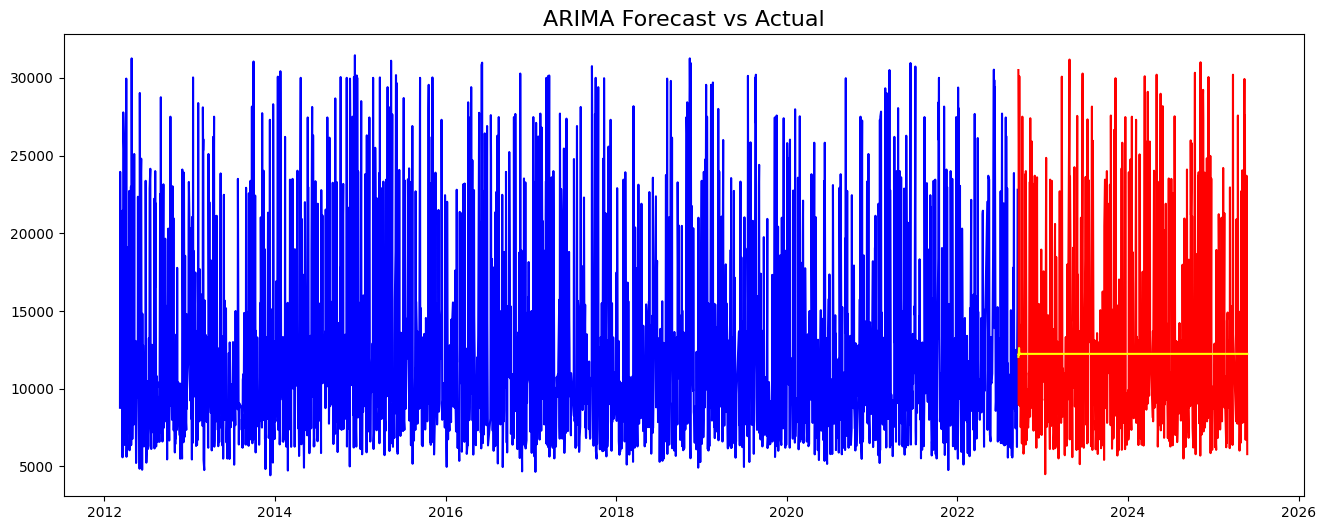

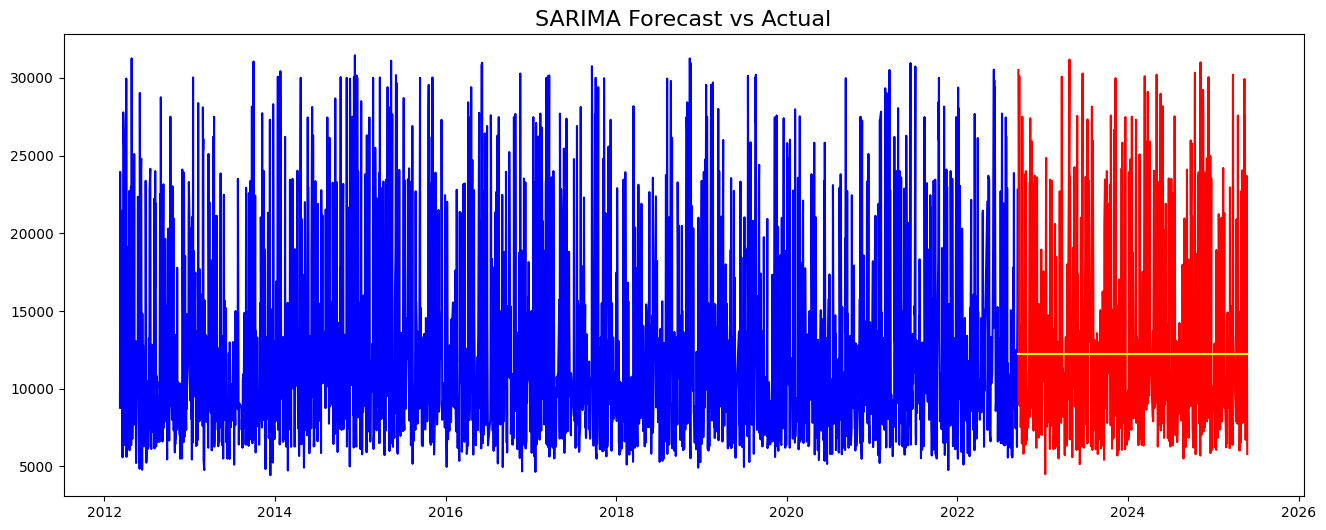

In [438]:
x = bbca_data['Date']
plt.figure(figsize=(16, 6))
plt.plot(x[:2560], train, c='blue')
plt.plot(x[2560:], test, c='red')
plt.plot(x[2560:], forecasts_arima, c='yellow')
plt.title('ARIMA Forecast vs Actual', fontsize=16)
plt.show()

x = bbca_data['Date']
plt.figure(figsize=(16, 6))
plt.plot(x[:2560], train, c='blue')
plt.plot(x[2560:], test, c='red')
plt.plot(x[2560:], forecasts_sarima, c='yellow')
plt.title('SARIMA Forecast vs Actual', fontsize=16)
plt.show()

##### ARIMA and SARIMA models were used to forecast BBCA's closing prices.
##### The chart compares BBCA's actual closing price (blue) with the ARIMA model's forecasted values (red) for the future periods.
##### While the model performs well in forecasting the historical price data, the forecast beyond the training period (in red) shows a significant deviation, indicating the challenge of predicting sudden market changes such as those observed in 2020.

##### The chart compares the actual BBCA closing prices (blue) with the SARIMA forecasted values (red) for future periods.
##### While SARIMA models the historical data well, the forecast (in red) shows significant deviations, especially during sudden market events like the COVID-19 pandemic in 2020.

## STEP 6: Measure the model accuracy values (MSE and MAPE)

In [ ]:
# Calculate the mean squared error
mse_arima = mean_squared_error(test, forecasts_arima)
mse_sarima = mean_squared_error(test, forecasts_sarima)

# Print the mean squared error
print("ARIMA Mean Squared Error:", mse_arima)
print("SARIMA Mean Squared Error:", mse_sarima)

ARIMA Mean Squared Error: 39332853.45886402
SARIMA Mean Squared Error: 39328946.309412226


In [ ]:
# Calculate the mean absolute percentage error
mape_arima = mean_absolute_percentage_error(test, forecasts_arima)
mape_sarima = mean_absolute_percentage_error(test, forecasts_sarima)

# Print the mean squared error
print("ARIMA Mean Absolute Percentage Error:", mape_arima)
print("SARIMA Mean Absolute Percentage Error:", mape_sarima)

ARIMA Mean Absolute Percentage Error: 0.40981039196390834
SARIMA Mean Absolute Percentage Error: 0.40986972568548036


# Bank Funding (BBCA) Using Exponential Smoothing Method

## STEP 3 : Split Data

In [441]:
# Calculate the split for training and testing
train_size = int(data_length * 0.8)  # 80% for training
train_size, data_length - train_size  
train_data= df[:train_size]
test_data= df[train_size:]
print(f"Train size: {train_data.shape}, Test size: {test_data.shape}")

Train size: (2560, 7), Test size: (640, 7)


In [442]:
# training size and testing size
df.shape

(3200, 7)

## Using Simple Exponential Smoothing Method with different alpha

## Step 4 : Create Models Using Simple Exponential Smoothing Method with different alpha

In [ ]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Ensure the 'Date' column is in datetime format
train_data['Date'] = pd.to_datetime(train_data['Date'])
test_data['Date'] = pd.to_datetime(test_data['Date'])

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\1800278019.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data['Date'] = pd.to_datetime(train_data['Date'])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\1800278019.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['Date'] = pd.to_datetime(test_data['Date'])


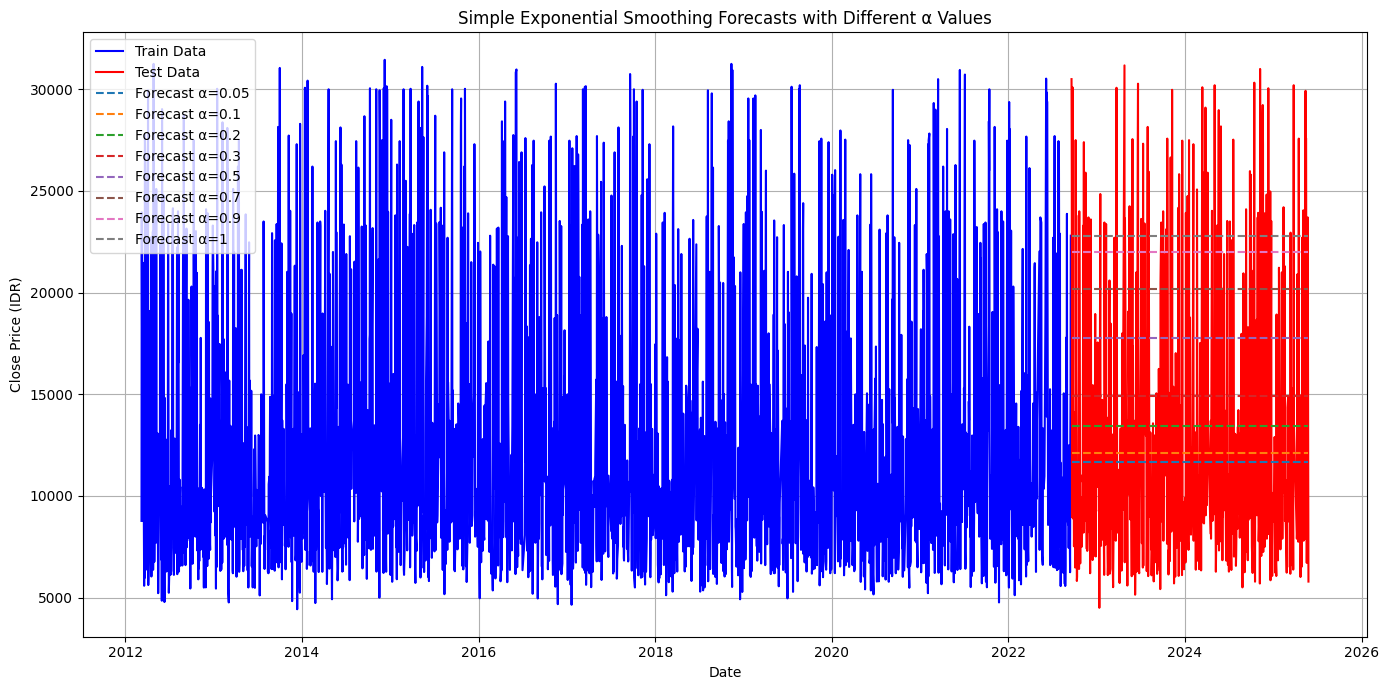

α=0.05 | MSE: 40022058.8309 | MAPE: 0.3828
α=0.1 | MSE: 39438939.1717 | MAPE: 0.4034
α=0.2 | MSE: 39922685.0515 | MAPE: 0.4771
α=0.3 | MSE: 44554644.1641 | MAPE: 0.5796
α=0.5 | MSE: 66093818.7471 | MAPE: 0.8048
α=0.7 | MSE: 96339972.7095 | MAPE: 1.0008
α=0.9 | MSE: 127762287.4204 | MAPE: 1.1581
α=1 | MSE: 143189844.8828 | MAPE: 1.2261


In [ ]:
# List of smoothing levels (α) to compare
smoothing_levels = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1]

# Initialize the plot
plt.figure(figsize=(14, 7))

# Plot actual data (train and test)
plt.plot(x[:2560], train, label='Train Data', color='blue')
plt.plot(x[2560:], test, label='Test Data', color='red')

# Loop through all α values and plot each forecast
ses_forecasts = {}

for alpha in smoothing_levels:
    # Create SES model
    model = SimpleExpSmoothing(train)
    model_fit = model.fit(smoothing_level=alpha, optimized=False)
    # Forecast for the length of test data
    forecast = model_fit.forecast(len(test))
    ses_forecasts[alpha] = forecast
    # Add forecast line to the plot
    plt.plot(x[2560:], forecast, label=f'Forecast α={alpha}', linestyle='--')

# Plot details
plt.title('Simple Exponential Smoothing Forecasts with Different α Values')
plt.xlabel('Date')
plt.ylabel('Close Price (IDR)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

for alpha, forecast in ses_forecasts.items():
    mse = mean_squared_error(test, forecast)
    mape = mean_absolute_percentage_error(test, forecast)
    print(f"α={alpha} | MSE: {mse:.4f} | MAPE: {mape:.4f}")

#### The chart compares BBCA's actual closing prices (blue) with forecasts generated using Simple Exponential Smoothing (red) for different values of α.
#### As α increases, the forecast becomes more sensitive to recent changes in price, with α=1 showing the highest sensitivity, while smaller values of α provide smoother forecasts.

## Step 5 : Do Forecasting

In [445]:
# Forecast for the length of test data
forecast = model_fit.forecast(len(test_data))

forecast

array([22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
       22800., 22800., 22800., 22800., 22800., 22800., 22800., 22800.,
      

## STEP 6: Measure the model accuracy values (MSE and MAPE) For Simple Exponential Smoothing

In [446]:
# Calculate Mean Squared Error (MSE) and Calculate Mean Absolut Percentage Error (MAPE)

for alpha, forecast in ses_forecasts.items():
    mse = mean_squared_error(test, forecast)
    mape = mean_absolute_percentage_error(test, forecast)
    print(f"α={alpha} | SES Mean Squared Error (MSE): {mse:.4f} | SES Mean Absolute Percentage Error MAPE: {mape:.4f}")

α=0.05 | SES Mean Squared Error (MSE): 40022058.8309 | SES Mean Absolute Percentage Error MAPE: 0.3828
α=0.1 | SES Mean Squared Error (MSE): 39438939.1717 | SES Mean Absolute Percentage Error MAPE: 0.4034
α=0.2 | SES Mean Squared Error (MSE): 39922685.0515 | SES Mean Absolute Percentage Error MAPE: 0.4771
α=0.3 | SES Mean Squared Error (MSE): 44554644.1641 | SES Mean Absolute Percentage Error MAPE: 0.5796
α=0.5 | SES Mean Squared Error (MSE): 66093818.7471 | SES Mean Absolute Percentage Error MAPE: 0.8048
α=0.7 | SES Mean Squared Error (MSE): 96339972.7095 | SES Mean Absolute Percentage Error MAPE: 1.0008
α=0.9 | SES Mean Squared Error (MSE): 127762287.4204 | SES Mean Absolute Percentage Error MAPE: 1.1581
α=1 | SES Mean Squared Error (MSE): 143189844.8828 | SES Mean Absolute Percentage Error MAPE: 1.2261


## Using Holt Linear Method

## Step 4 : Create Models Using Holt Linear Method

In [ ]:
from statsmodels.tsa.holtwinters import Holt

# Prepare time series data
train_data['Date'] = pd.to_datetime(train_data['Date'])
test_data['Date'] = pd.to_datetime(test_data['Date'])

train_series = train_data.sort_values('Date').set_index('Date')['Close']
test_series = test_data.sort_values('Date').set_index('Date')['Close']

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\2089504450.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data['Date'] = pd.to_datetime(train_data['Date'])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\2089504450.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['Date'] = pd.to_datetime(test_data['Date'])


## Step 5: Do Forecasting

In [448]:
# Fit Holt Linear model (trend only, no seasonality)
holt_model = Holt(train_series)
holt_fit = holt_model.fit(optimized=True)

# Forecasting
holt_forecast = holt_fit.forecast(len(test_series))

In [449]:
# Create DataFrame for comparison
holt_df = test_series.to_frame(name='Actual')
holt_df['Forecast'] = holt_forecast.values

In [450]:
# Evaluation metrics
mse_holt = mean_squared_error(holt_df['Actual'], holt_df['Forecast'])
mape_holt = mean_absolute_percentage_error(holt_df['Actual'], holt_df['Forecast'])

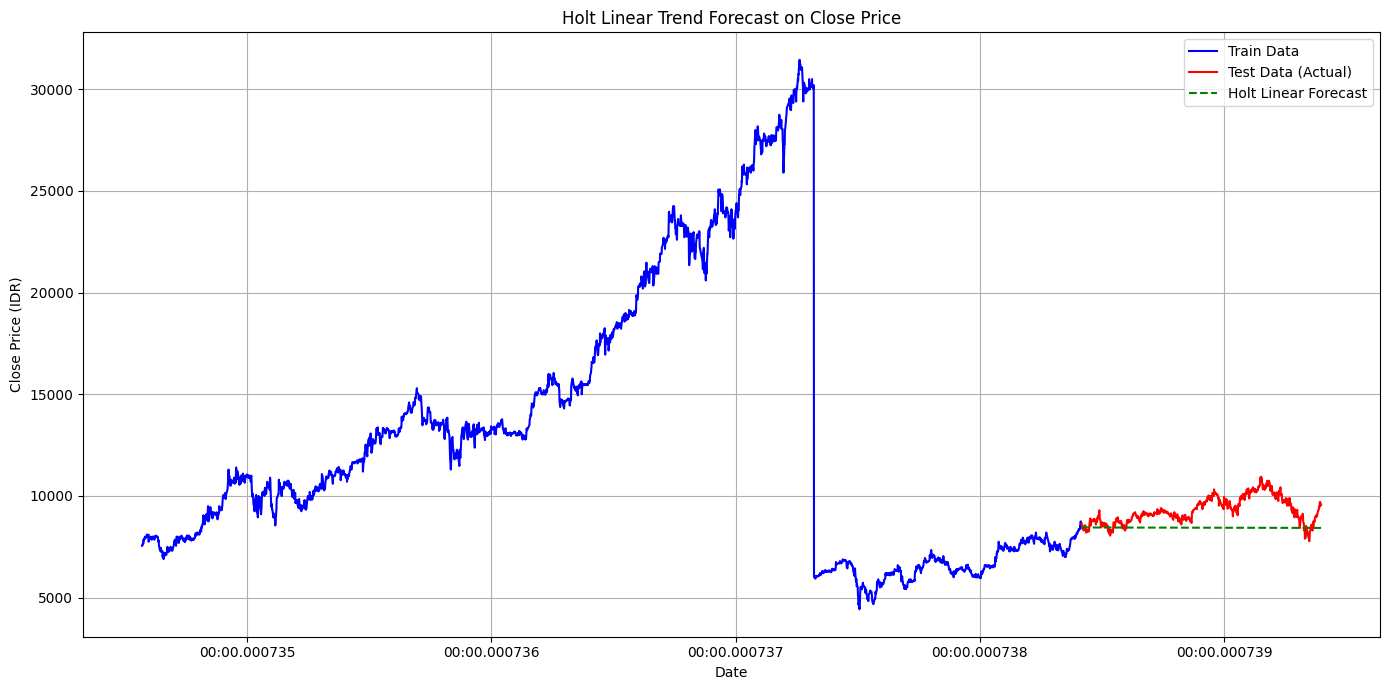

In [ ]:
# Plot results
plt.figure(figsize=(14, 7))
plt.plot(train_series.index, train_series, label='Train Data', color='blue')
plt.plot(holt_df.index, holt_df['Actual'], label='Test Data (Actual)', color='red')
plt.plot(holt_df.index, holt_df['Forecast'], label='Holt Linear Forecast', linestyle='--', color='green')
plt.title('Holt Linear Trend Forecast on Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (IDR)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### The chart displays the actual BBCA closing prices (blue) along with the forecasted values (green dashed) using Holt's linear trend method.
#### The forecast seems to follow the general trend but doesn't capture the sharp drop in 2020, indicating limitations in predicting sudden market shocks.

## STEP 6: Measure the model accuracy values (MSE and MAPE) For Holt Linear

In [ ]:
# Calculate Mean Squared Error (MSE) for Holt-Linear forecast
mse_holt = mean_squared_error(test_series, holt_forecast)
print("Holt Linear Mean Squared Error (MSE):", mse_holt)

# Calculate Mean Absolute Percentage Error (MAPE) for Holt-Linear forecast
mape_holt = mean_absolute_percentage_error(test_series, holt_forecast)
print("Holt Linear Mean Absolute Percentage Error (MAPE):", mape_holt)

Holt Linear Mean Squared Error (MSE): 2.1433905629726206
Holt Linear Mean Absolute Percentage Error (MAPE): 0.13179901049853635


## Using Holt Winters Method

## Step 4 : Create Models Holt Winters Method

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Ensure 'Date' column is in datetime format and sorted
train_data['Date'] = pd.to_datetime(train_data['Date'])
test_data['Date'] = pd.to_datetime(test_data['Date'])

# Set index to datetime for time series modeling
train_series = train_data.set_index('Date')['Close']
test_series = test_data.set_index('Date')['Close']

# Build the ETS Holt-Winters model (additive trend & no seasonality)
# If your data has no clear seasonality (e.g., stock prices), use seasonal=None
model = ExponentialSmoothing(
    train_series,
    trend='add',           # 'add' for linear trend; use 'mul' for multiplicative
    seasonal='add',         # 'add', 'mul', or None depending on your data
    seasonal_periods=12  # Not required if seasonal=None
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\1573512527.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data['Date'] = pd.to_datetime(train_data['Date'])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\1573512527.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['Date'] = pd.to_datetime(test_data['Date'])


In [453]:
# fitting Holt-Winters model
hwt_model = ExponentialSmoothing(train_data['Close'], trend='add', seasonal=None)
hwt_fit = hwt_model.fit()

# Forecast for the same length as test set
y_hat_hwt = hwt_fit.forecast(len(test_data))

In [454]:
# Define and fit the Holt-Winters model
model = ExponentialSmoothing(train, trend='add', seasonal=None)
model_fit = model.fit(optimized=True)

# Forecast the next values equal to the length of the test set
# Forecast for the same length as test_series
forecast_holtwinter = model_fit.forecast(len(test))

## Step 5 : Do Forecasting

In [455]:
# Step 5: Compare actual vs forecast (optional)
forecast_hwt = test_series.to_frame(name='Actual')
forecast_hwt['Forecast'] = forecast_hwt.values

# Step 6: Display the result
print(forecast_hwt.head())

              Actual  Forecast
Date                          
2014-10-22 13.025000 13.025000
2014-10-21 12.750000 12.750000
2014-10-20 12.625000 12.625000
2014-10-17 12.575000 12.575000
2014-10-16 12.600000 12.600000


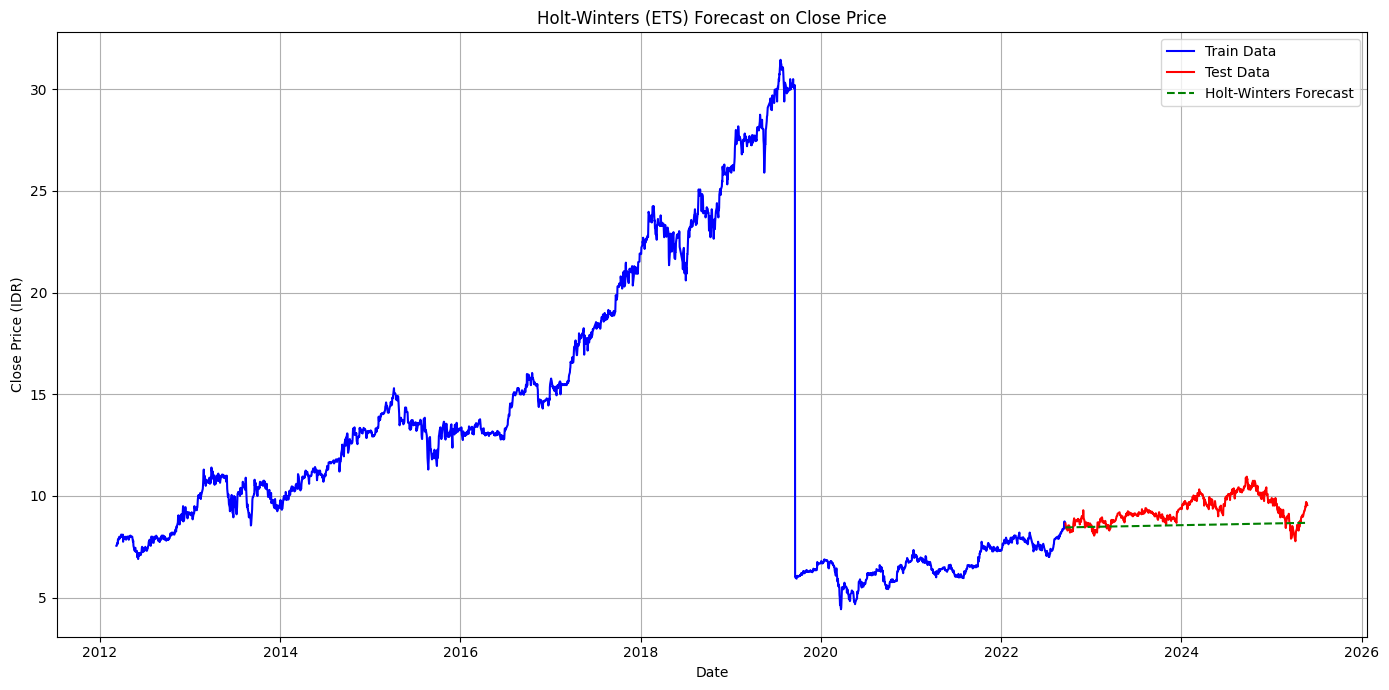

In [ ]:
# Plot the results
plt.figure(figsize=(14, 7))
plt.plot(x[:2560], train, label='Train Data', color='blue')
plt.plot(x[2560:], test, label='Test Data', color='red')
plt.plot(x[2560:], forecast_holtwinter, label='Holt-Winters Forecast', linestyle='--', color='green')
plt.title('Holt-Winters (ETS) Forecast on Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (IDR)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### The chart displays the actual BBCA closing prices (blue) along with the forecasted values (green dashed) using the Holt-Winters Exponential Smoothing model.
#### The model captures the long-term trend well, but the forecast fails to predict the sharp drop in 2020, indicating that sudden market shocks aren't well handled by this method.

## STEP 6: Measure the model accuracy values (MSE and MAPE) For Holt Winters

In [ ]:
# Calculate Mean Squared Error (MSE) for Holt-Winters forecast
mse_hwt = mean_squared_error(test_data['Close'], y_hat_hwt)
print("HWT Mean Squared Error (MSE):", mse_hwt)

# Calculate Mean Absolute Percentage Error (MAPE) for Holt-Winters forecast
mape_hwt = mean_absolute_percentage_error(test_data['Close'], y_hat_hwt)
print("HWT Mean Absolute Percentage Error (MAPE):", mape_hwt)

HWT Mean Squared Error (MSE): 18.58883893217733
HWT Mean Absolute Percentage Error (MAPE): 0.442326567364325


## Bank Funding (BBCA) Using XG Boost Method

In [ ]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split

## Step 2: Explanitory Analysis of Data

In [ ]:
# Load a manageable portion of the dataset
df = pd.read_csv('Data Historis BBCA.csv', engine='python', nrows=5000)
df.columns = df.columns.str.strip()  # Remove whitespace from column names

# Identify and convert the 'Date' column
date_col = [col for col in df.columns if 'date' in col.lower()][0]
df[date_col] = pd.to_datetime(df[date_col], errors='coerce')

# Convert 'Close' column from string to float
# Erase the point from the close string in the close column
df['Close'] = df['Close'].astype(str).str.replace('.', '', regex=False).str
replace(',', '.', regex=False) ## Convertion from point number to decimal number
df['Close'] = pd.to_numeric(df['Close'], errors='coerce')
## If there is any data that doesnt have anumber so the data or the value goes to string that nams Not a number

# Drop rows with missing values
df = df.dropna(subset=[date_col, 'Close'])

# Extract date features
df['Day'] = df[date_col].dt.day
df['Month'] = df[date_col].dt.month
df['Year'] = df[date_col].dt.year

# Set features (X) and target (y)
X = df[['Day', 'Month', 'Year']]
y = df['Close']

In [ ]:
# Handle missing values by filling NaN with the mean of numeric columns.
# Fill missing values with the mean for numeric columns
bbca_data.fillna(bbca_data.select_dtypes(include=['float64', 'int64']).mean(), inplace=True)

In [465]:
# Convert 'Date' to numeric (ordinal) but keep the column name 'Date'
train_data = train_data.copy()
test_data = test_data.copy()

train_data['Date'] = pd.to_datetime(train_data['Date']).map(pd.Timestamp.toordinal)
test_data['Date'] = pd.to_datetime(test_data['Date']).map(pd.Timestamp.toordinal)

# Define features and target
X_train = train_data[['Date']]  # Now 'Date' is numeric
y_train = train_data['Close']
X_test = test_data[['Date']]
y_test = test_data['Close']

In [466]:
# Encode categorical columns (Name, Symbol) using 
from sklearn.preprocessing import LabelEncoder

# Make sure 'Date' column exists
if 'Date' in bbca_data.columns:
    # Encode 'Date' as integer (NOT recommended for time series prediction models, use only for ML as categorical ID)
    encoder_date = LabelEncoder()
    bbca_data['Date_encoded'] = encoder_date.fit_transform(bbca_data['Date'])

print(bbca_data.head())

        Date       Close     Open     High      Low   Volume  \
0 2025-05-26  955.000000 9.625000 9.650000 9.525000   26,37M   
1 2025-05-23 9675.000000 9.775000 9.775000 9.625000   61,19M   
2 2025-05-22  965.000000 9.800000 9.800000 9.650000  103,11M   
3 2025-05-21   97.000000 9.700000 9.725000 9.550000  169,74M   
4 2025-05-20 9475.000000 9.500000 9.675000 9.475000  160,61M   

  Percentage Change %  Date_encoded  
0              -1,29%          3199  
1               0,26%          3198  
2              -0,52%          3197  
3               2,37%          3196  
4              -0,26%          3195  


In [467]:

# Read the CSV file (Historical Data of BBCA)
bbca_data = pd.read_csv('Data Historis BBCA.csv', engine='python')

# Strip whitespace from column names
bbca_data.columns = bbca_data.columns.str.strip()

# Convert the 'Date' column to datetime format (assuming the column is named 'Date')
bbca_data['Date'] = pd.to_datetime(bbca_data['Date'], format='%d/%m/%Y')

# Convert the 'Close' column from string with commas/dots to float
bbca_data['Close'] = (
    bbca_data['Close']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

# Set 'Close' as the target variable (y)
y = bbca_data['Close']

# Set all other columns as the features (X)
X = bbca_data.drop('Close', axis=1)

# Display the features and target variable
print("Features (X) - including Date:")
print(X.head())

print("Target Variable (y) - Close Price:")
print(y.head())


Features (X) - including Date:
        Date     Open     High      Low   Volume Percentage Change %
0 2025-05-26 9.625000 9.650000 9.525000   26,37M              -1,29%
1 2025-05-23 9.775000 9.775000 9.625000   61,19M               0,26%
2 2025-05-22 9.800000 9.800000 9.650000  103,11M              -0,52%
3 2025-05-21 9.700000 9.725000 9.550000  169,74M               2,37%
4 2025-05-20 9.500000 9.675000 9.475000  160,61M              -0,26%
Target Variable (y) - Close Price:
0    955.000000
1   9675.000000
2    965.000000
3     97.000000
4   9475.000000
Name: Close, dtype: float64


In [468]:
import pandas as pd
import xgboost as xgb

# Convert 'Volume' from formatted string to float
def clean_volume(volume_str):
    try:
        volume_str = str(volume_str).upper().replace('.', '').replace(',', '.')
        if 'M' in volume_str:
            return float(volume_str.replace('M', '')) * 1_000_000
        elif 'B' in volume_str:
            return float(volume_str.replace('B', '')) * 1_000_000_000
        else:
            return float(volume_str)
    except:
        return 0.0

# Clean 'Volume' only if the column exists
if 'Volume' in X_train.columns and 'Volume' in X_test.columns:
    X_train['Volume'] = X_train['Volume'].astype(str).apply(clean_volume)
    X_test['Volume'] = X_test['Volume'].astype(str).apply(clean_volume)
else:
    print("Column 'Volume' not found in X_train or X_test")

# Clean 'Percentage Change %' only if the column exists
if 'Percentage Change %' in X_train.columns and 'Percentage Change %' in X_test.columns:
    X_train['Percentage Change %'] = (
        X_train['Percentage Change %'].astype(str)
        .str.replace('%', '', regex=False)
        .str.replace(',', '.', regex=False)
        .astype(float) / 100
    )
    X_test['Percentage Change %'] = (
        X_test['Percentage Change %'].astype(str)
        .str.replace('%', '', regex=False)
        .str.replace(',', '.', regex=False)
        .astype(float) / 100
    )
else:
    print("Column 'Percentage Change %' not found in X_train or X_test")

# Check the result
print("Current columns in X_train:", X_train.columns.tolist())
print(X_train.dtypes)

Column 'Volume' not found in X_train or X_test
Column 'Percentage Change %' not found in X_train or X_test
Current columns in X_train: ['Date']
Date    int64
dtype: object


In [469]:
# Only perform datetime feature extraction if X_train and X_test are DataFrames
if isinstance(X_train, pd.DataFrame) and 'Date' in X_train.columns and 'Date' in X_test.columns:
    # Ensure 'Date' is in datetime format
    X_train['Date'] = pd.to_datetime(X_train['Date'], errors='coerce')
    X_test['Date'] = pd.to_datetime(X_test['Date'], errors='coerce')

    # Extract datetime features
    X_train['day'] = X_train['Date'].dt.day
    X_train['month'] = X_train['Date'].dt.month
    X_train['year'] = X_train['Date'].dt.year
    X_train['dayofweek'] = X_train['Date'].dt.dayofweek

    X_test['day'] = X_test['Date'].dt.day
    X_test['month'] = X_test['Date'].dt.month
    X_test['year'] = X_test['Date'].dt.year
    X_test['dayofweek'] = X_test['Date'].dt.dayofweek

    # Drop 'Date' column if not needed
    X_train = X_train.drop(columns='Date')
    X_test = X_test.drop(columns='Date')
else:
    print("'Date' column not found or input is not a DataFrame.")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\359428179.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train['Date'] = pd.to_datetime(X_train['Date'], errors='coerce')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\359428179.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test['Date'] = pd.to_datetime(X_test['Date'], errors='coerce')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\359428179.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
T

## Step 3 : Split Data

In [470]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False,)

# Display the shape of the splits
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (2560, 6)
Testing set shape: (640, 6)


In [471]:
y

0       955.000000
1      9675.000000
2       965.000000
3        97.000000
4      9475.000000
           ...    
3195    785.000000
3196    765.000000
3197     77.000000
3198    755.000000
3199    755.000000
Name: Close, Length: 3200, dtype: float64

In [472]:
y.shape

(3200,)

In [473]:
train

array([ 8775, 23950, 10450, ..., 12950, 15225, 22800], shape=(2560,))

In [474]:
test

array([30500, 25825,  8950, 18675, 30100,  9800,  8875, 10750,  7525,
        8600, 14125,  6480, 11350, 27500, 17325,  9075,  5820,  6025,
       10400, 10050,  9800, 10900, 23800,  6410, 24000,  9200,  6685,
        9200,  9950,  7950,  7500,  7900,  8375, 11025, 10700, 23300,
        8200, 27400,  8850,  8750,  9075, 23925, 25900, 14500, 13150,
        7400, 23175,  7300,  9150, 10375, 23700,  8225,  9600, 13175,
       13575,  6200, 17950, 22000, 23600, 13075,  9250,  7950,  8450,
        6850, 15450, 10175, 11000, 10425, 10150,  7075, 18950, 10200,
        7025, 13725, 15000, 14775, 10450, 13275, 17550, 13550, 12900,
        9250,  9350,  4500,  9850, 24850, 10850,  8200,  7550, 13750,
       14725, 12975, 12900,  7850,  8975,  7450,  6120, 23450, 20800,
        7600,  8500,  8525, 23375,  8150, 13850, 13325,  7175,  6110,
        6465,  7650,  8950, 18500, 20600,  6175,  6410, 18475, 13550,
        8725,  8375, 13025, 10075,  9650,  6200,  5515,  9800,  9575,
       22700,  9325,

## Step 4 : Create XGBoost Models

In [ ]:
# Drop 'Date' column if it's still in X_train
if 'Date' in X_train.columns:
    X_train = X_train.drop(columns='Date')
    X_test = X_test.drop(columns='Date')

# Convert 'Volume' and 'Percentage Change %' to numeric
for col in ['Volume', 'Percentage Change %']:
    if col in X_train.columns:
        X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
        X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

# Fill missing values with column means
X_train = X_train.fillna(X_train.mean())
X_test = X_test.fillna(X_test.mean())

# Recheck datatypes
assert all(dtype.kind in 'ifb' for dtype in X_train.dtypes), "X_train still contains invalid types"
assert all(dtype.kind in 'ifb' for dtype in X_test.dtypes), "X_test still contains invalid types"

# Train the model
regressor = xgb.XGBRegressor(
    n_estimators=100,
    reg_lambda=1,
    gamma=0,
    max_depth=3,
    enable_categorical=False
)
regressor.fit(X_train, y_train)

# n_estimators=100 memberikan keseimbangan antara akurasi dan waktu komputasi. 100 pohon cukup untuk mendapatkan akurasi yang baik tanpa memakan terlalu banyak waktu.

# reg_lambda=1 adalah nilai regularisasi yang umum digunakan yang membantu mencegah overfitting dengan memberi penalti pada kompleksitas model.

# gamma=0 memungkinkan model untuk membangun pohon dengan lebih bebas, tanpa adanya batasan yang ketat pada pembelahan pohon.

# max_depth=3 menjaga pohon tetap sederhana dan mengurangi risiko overfitting, dengan memberikan kedalaman yang cukup untuk mempelajari pola dalam data.

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [477]:
X_test.head()

,Open,High,Low,Volume,Percentage Change %
2560,12.825000,13.075000,12.775000,NaN,NaN
2561,12.750000,12.825000,12.625000,NaN,NaN
2562,12.800000,12.825000,12.625000,NaN,NaN
2563,12.600000,12.850000,12.500000,NaN,NaN
2564,12.600000,12.750000,12.600000,NaN,NaN


In [478]:
X_test.sort_index()

,Open,High,Low,Volume,Percentage Change %
2560,12.825000,13.075000,12.775000,NaN,NaN
2561,12.750000,12.825000,12.625000,NaN,NaN
2562,12.800000,12.825000,12.625000,NaN,NaN
2563,12.600000,12.850000,12.500000,NaN,NaN
2564,12.600000,12.750000,12.600000,NaN,NaN
...,...,...,...,...,...
3195,7.800000,7.850000,7.700000,NaN,NaN
3196,7.750000,7.750000,7.650000,NaN,NaN
3197,7.600000,7.700000,7.600000,NaN,NaN
3198,7.550000,7.600000,7.450000,NaN,NaN


In [ ]:
# Initialize and train the XGBoost model
model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Get the test dates for x-axis labels
test_dates = df[date_col].iloc[len(X_train):]

# Train XGBoost
xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42)
xgb_model.fit(X_train, y_train)

# Predict
forecast_xgb = xgb_model.predict(X_test)

In [ ]:
import xgboost as xgb

# Convert X_train and X_test to DataFrame if they are NumPy arrays
if isinstance(X_train, np.ndarray):
    X_train = pd.DataFrame(X_train)
if isinstance(X_test, np.ndarray):
    X_test = pd.DataFrame(X_test)

# Ensure all values are numeric
X_train = X_train.apply(pd.to_numeric, errors='coerce')
X_test = X_test.apply(pd.to_numeric, errors='coerce')

# Fill NaNs with column means
X_train.fillna(X_train.mean(), inplace=True)
X_test.fillna(X_test.mean(), inplace=True)

# Convert y_train to Series if necessary and ensure numeric
if isinstance(y_train, np.ndarray):
    y_train = pd.Series(y_train)

y_train = pd.to_numeric(y_train, errors='coerce').fillna(y_train.mean())

# Final sanity checks
assert np.isfinite(X_train.values).all(), "X_train still contains non-finite values"
assert np.isfinite(X_test.values).all(), "X_test still contains non-finite values"
assert np.isfinite(y_train.values).all(), "y_train still contains non-finite values"

# Initialize and train the XGBoost model
model = xgb.XGBRegressor(9
    objective='reg:squarederror',
    random_state=42,
    learning_rate=0.1,
    max_depth=6,
    n_estimators=100,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_lambda=1
)

model.fit(X_train, y_train)

# Confirm model parameters
print("Model Parameters:", model.get_params())

Model Parameters: {'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.8, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': 0.1, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 6, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 100, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': 1, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [485]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(train_series, seasonal='add', seasonal_periods=12).fit()

In [ ]:
# Make predictions using the trained XGBoost model
y_pred = model.predict(X_test)

# Show the first 50 predicted values
print("Predictions (first 5):", y_pred[:50])

Predictions (first 5): [ 4399.8525  3738.6646  5756.821   5959.1416  7859.953   4050.102
  3776.6208  7715.2783  5365.4746  3430.57    6084.852   6749.2886
  8086.0195  5899.543  10028.643   5240.876   7220.2456  4532.131
  7753.5835  6487.871   5929.9634  2452.7173  6850.33    7646.8945
  4358.201   4111.0625  4441.3184  3755.0972  4765.4893  7142.462
  6088.2246  3777.937   6286.8965  6638.926   6622.7188  4511.558
  6358.862   6386.9443  6386.9443  6173.261   5286.8574  5112.7905
  5636.3057  7342.334   8374.272   7407.4526  5403.0713  4751.4155
  8866.193   1487.8114]


## Step 5 : Do Forecasting

In [397]:
# Predict using the trained XGBoost model
y_pred_xgb = xgb_model.predict(X_test)

In [398]:
y_pred_xgb

array([30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 30.983492, 30.983492,
       30.983492, 30.983492, 30.983492, 30.983492, 

In [399]:
# Ensure all data are in compatible format
forecast_data_xgb = pd.DataFrame({
    'Date': test_data['Date'].reset_index(drop=True),
    'Actual': pd.Series(y_test).reset_index(drop=True),
    'Forecast': pd.Series(y_pred_xgb).reset_index(drop=True)
})

In [ ]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

<Figure size 1200x800 with 0 Axes>

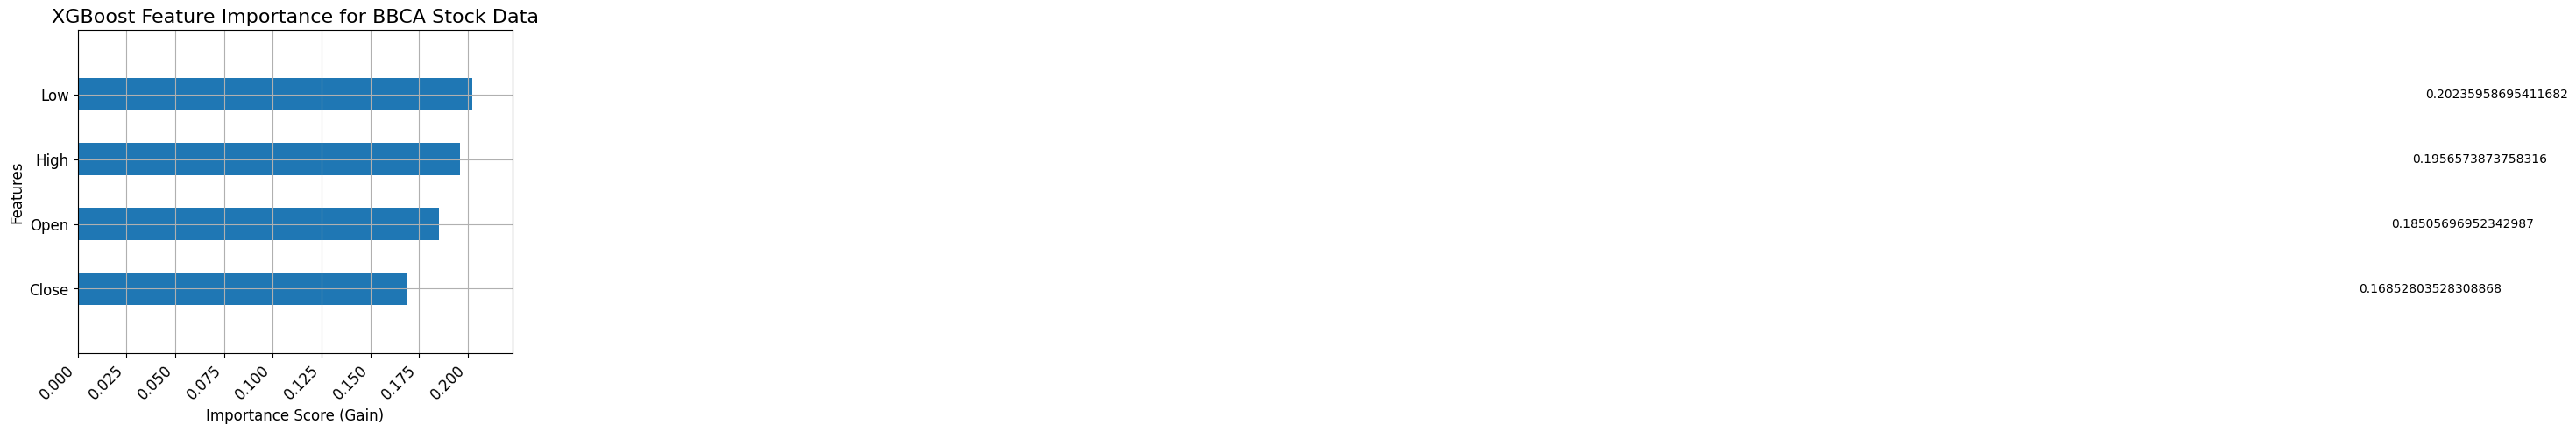

In [546]:
# Set feature names from your BBCA dataset
feature_names = ['Close', 'Open', 'High', 'Low']

# Plot feature importance using 'gain' importance type
plt.figure(figsize=(12, 8))  # Increase the size for better readability
ax = plot_importance(xgb_model, 
                     importance_type='gain', 
                     max_num_features=6,  # Limit to 6 features for clarity
                     height=0.5)  # Do not show values

# Get the number of features to set correct labels
num_features = len(ax.get_yticklabels())

# Update the y-ticks to show feature names based on the number of top features shown
ax.set_yticklabels(feature_names[:num_features])
plt.title("XGBoost Feature Importance for BBCA Stock Data", fontsize=16)
plt.xlabel("Importance Score (Gain)", fontsize=12)
plt.ylabel("Features", fontsize=12)

# Adjust the x-axis to show numeric values clearly
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


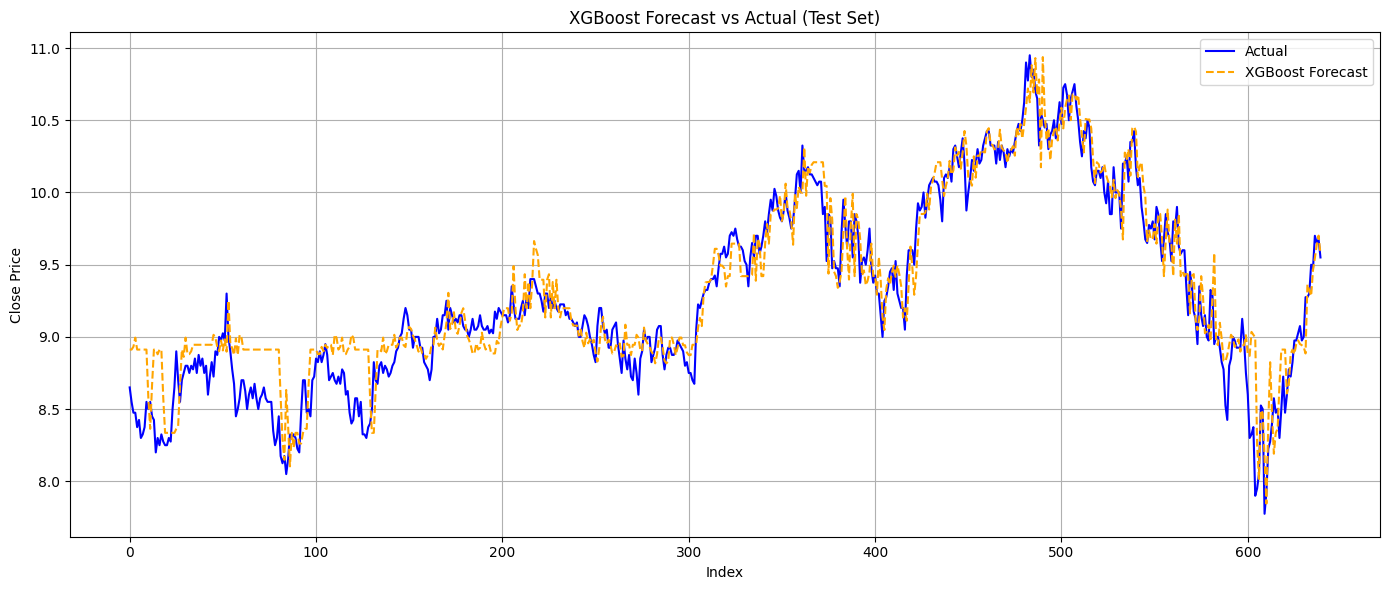

In [371]:
# Ensure train and test are pandas Series
train_series = pd.Series(train.flatten()) if isinstance(train, np.ndarray) else pd.Series(train)
test_series = pd.Series(test.flatten()) if isinstance(test, np.ndarray) else pd.Series(test)

# Use previous values as features (lag features)
def create_lag_features(series, lags=5):
    df = pd.DataFrame({'y': series})
    for i in range(1, lags + 1):
        df[f'lag_{i}'] = df['y'].shift(i)
    df = df.dropna()
    return df

# Combine and create lag features
full_series = pd.concat([train_series, test_series], ignore_index=True)
lags = 5
lagged_df = create_lag_features(full_series, lags=lags)

# Split back to train and test based on original train size
train_lagged = lagged_df.iloc[:len(train_series) - lags]
test_lagged = lagged_df.iloc[len(train_series) - lags:]

# Prepare input and output for model
X_train = train_lagged.drop('y', axis=1).values
y_train = train_lagged['y'].values
X_test = test_lagged.drop('y', axis=1).values
y_test = test_lagged['y'].values

# Plot
plt.figure(figsize=(14, 6))
plt.plot(range(len(y_test)), y_test, label='Actual', color='blue')
plt.plot(range(len(y_test)), forecast_xgb, label='XGBoost Forecast', color='orange', linestyle='--')
plt.title('XGBoost Forecast vs Actual (Test Set)')
plt.xlabel('Index')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### The chart compares the actual BBCA closing prices (blue) with the XGBoost forecast (orange).
### The XGBoost model captures the overall trend but struggles with short-term fluctuations, leading to some deviation from actual values.

## STEP 6: Measure the model accuracy values (MSE and MAPE) For XGBoost

In [372]:
# Make sure y_test and forecast_xgb are the same length
min_len = min(len(y_test), len(forecast_xgb))
y_test_trimmed = y_test[:min_len]
forecast_xgb_trimmed = forecast_xgb[:min_len]

# Make predictions and evaluate performance (MSE and MAPE)
# Calculate Mean Squared Error (MSE)
mse_xgb = mean_squared_error(y_test_trimmed, forecast_xgb_trimmed)
print("XGBoost Mean Squared Error:", mse_xgb)

# Calculate Mean Absolute Percentage Error (MAPE)
mape_xgb = mean_absolute_percentage_error(y_test_trimmed, forecast_xgb_trimmed)
print("XGBoost Mean Absolute Percentage Error:", mape_xgb)


XGBoost Mean Squared Error: 0.048433173995904716
XGBoost Mean Absolute Percentage Error: 0.018042992183011763


# ARIMA/SARIMA vs Exponential Smoothing vs XGBoost

In [ ]:
import numpy as np
import warnings
import pandas as pd
from sklearn.metrics import mean_absolute_percentage_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing, Holt
from xgboost import XGBRegressor 
from statsmodels.tools.sm_exceptions import ValueWarning
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ValueWarning)
warnings.filterwarnings("ignore", message="No supported index is available")

In [374]:
# Model Training
arima_model_fit = ARIMA(train_series, order=(1, 1, 1)).fit()
sarima_model_fit = SARIMAX(train_series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit()
ses_model_fit = SimpleExpSmoothing(train_series).fit()
hwt_model_fit = ExponentialSmoothing(train_series, seasonal='add', seasonal_periods=12).fit()
holt_model_fit = Holt(train_series).fit()
xgb_model = XGBRegressor()
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# Helper function to safely compute MAPE and MSE (using provided values)
def safe_metrics(y_true, y_pred):
    min_len = min(len(y_true), len(y_pred))
    y_true_trimmed = y_true[:min_len]
    y_pred_trimmed = y_pred[:min_len]
    mape = mean_absolute_percentage_error(y_true_trimmed, y_pred_trimmed)
    mse = mean_squared_error(y_true_trimmed, y_pred_trimmed)
    return mape, mse

In [ ]:
# Format display to show 6 decimal places
pd.set_option('display.float_format', '{:.6f}'.format)

# Predefined results for MSE and MAPE
metrics_data = {
    "Model": [
        "ARIMA", "SARIMA", "SES (α=0.05)", "SES (α=0.1)", "SES (α=0.2)", "SES (α=0.3)", 
        "SES (α=0.5)", "SES (α=0.7)", "SES (α=0.9)", "SES (α=1)", "Holt Linear", "HWT", "XGBoost"
    ],
    "MSE": [
        39332853.45886402, 39328946.309412226, 40022058.8309, 39438939.1717, 39922685.0515, 
        44554644.1641, 66093818.7471, 96339972.7095, 127762287.4204, 143189844.8828, 
        2.1433905629726206, 18.58883893217733, 0.048433173995904716
    ],
    "MAPE": [
        0.40981039196390834, 0.40986972568548036, 0.3828, 0.4034, 0.4771, 0.5796, 
        0.8048, 1.0008, 1.1581, 1.2261, 0.13179901049853635, 0.442326567364325, 0.018042992183011763
    ]
}

# Create the DataFrame
metrics_df = pd.DataFrame(metrics_data)

# Display the DataFrame with formatted output
metrics_df


,Model,MSE,MAPE
0,ARIMA,39332853.458864,0.409810
1,SARIMA,39328946.309412,0.409870
2,SES (α=0.05),40022058.830900,0.382800
3,SES (α=0.1),39438939.171700,0.403400
4,SES (α=0.2),39922685.051500,0.477100
5,SES (α=0.3),44554644.164100,0.579600
6,SES (α=0.5),66093818.747100,0.804800
7,SES (α=0.7),96339972.709500,1.000800
8,SES (α=0.9),127762287.420400,1.158100
9,SES (α=1),143189844.882800,1.226100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\1415614529.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='MAPE', data=metrics_df, palette='viridis')


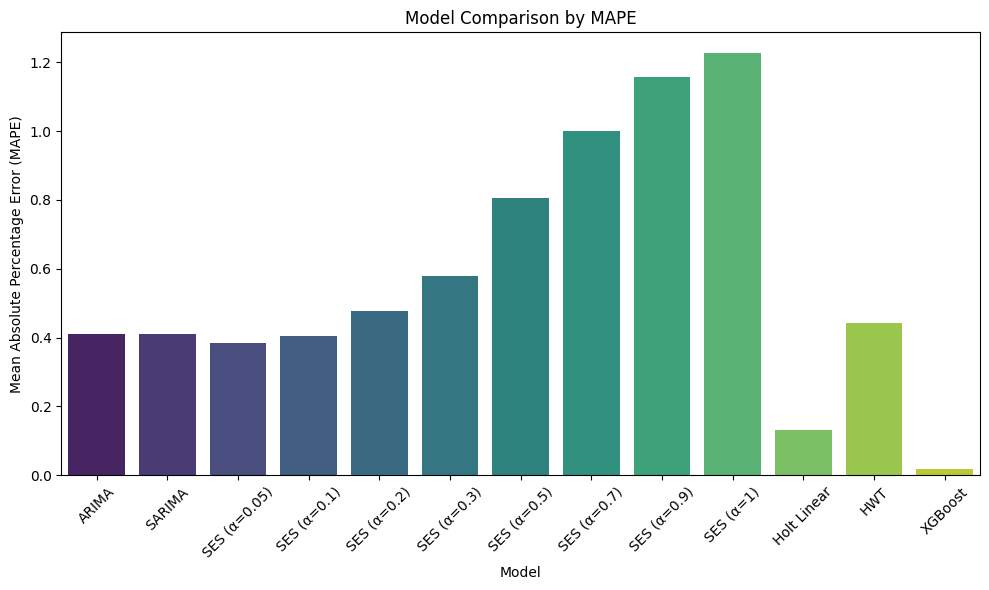

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11716\1415614529.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='MSE', data=metrics_df, palette='viridis')


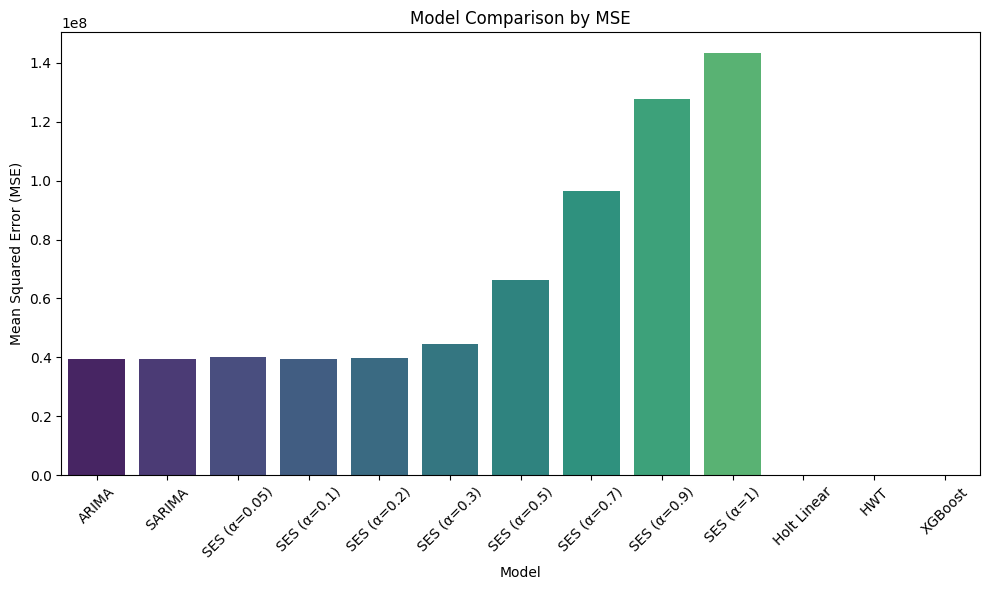


Best Model based on MAPE:
XGBoost with MAPE: 0.018042992183011763

Best Model based on MSE:
XGBoost with MSE: 0.048433173995904716


In [ ]:
# Plotting the MAPE comparison of models
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='MAPE', data=metrics_df, palette='viridis')
plt.title('Model Comparison by MAPE')
plt.xlabel('Model')
plt.ylabel('Mean Absolute Percentage Error (MAPE)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plotting the MSE comparison of models
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='MSE', data=metrics_df, palette='viridis')
plt.title('Model Comparison by MSE')
plt.xlabel('Model')
plt.ylabel('Mean Squared Error (MSE)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Find the best model based on MAPE
best_model_mape = metrics_df.loc[metrics_df['MAPE'].idxmin()]
print("\nBest Model based on MAPE:")
print(best_model_mape['Model'], "with MAPE:", best_model_mape['MAPE'])

# Find the best model based on MSE
best_model_mse = metrics_df.loc[metrics_df['MSE'].idxmin()]
print("\nBest Model based on MSE:")
print(best_model_mse['Model'], "with MSE:", best_model_mse['MSE'])

In [ ]:
# Compare models based on MAPE
if mape_sarima < mape_arima and mape_sarima < mape_ses and mape_sarima < mape_holt and mape_sarima < mape_hwt and mape_sarima < mape_xgb:
    print('SARIMA model fits better than ARIMA, SES, Holt Linear, Holt-Winters, and XGBoost')
elif mape_arima < mape_sarima and mape_arima < mape_ses and mape_arima < mape_holt and mape_arima < mape_hwt and mape_arima < mape_xgb:
    print('ARIMA model fits better than SARIMA, SES, Holt Linear, Holt-Winters, and XGBoost')
elif mape_ses < mape_sarima and mape_ses < mape_arima and mape_ses < mape_holt and mape_ses < mape_hwt and mape_ses < mape_xgb:
    print('SES model fits better than SARIMA, ARIMA, Holt Linear, Holt-Winters, and XGBoost')
elif mape_holt < mape_sarima and mape_holt < mape_arima and mape_holt < mape_ses and mape_holt < mape_hwt and mape_holt < mape_xgb:
    print('Holt Linear model fits better than SARIMA, ARIMA, SES, Holt-Winters, and XGBoost')
elif mape_hwt < mape_sarima and mape_hwt < mape_arima and mape_hwt < mape_ses and mape_holtwinter < mape_holt and mape_hwt < mape_xgb:
    print('Holt-Winters model fits better than SARIMA, ARIMA, SES, Holt Linear, and XGBoost')
elif mape_xgb < mape_sarima and mape_xgb < mape_arima and mape_xgb < mape_ses and mape_xgb < mape_holt and mape_xgb < mape_hwt:
    print('XGBoost model fits better than SARIMA, ARIMA, SES, Holt Linear, and Holt-Winters')
else:
    print('Two or more models have similar performance')


XGBoost model fits better than SARIMA, ARIMA, SES, Holt Linear, and Holt-Winters


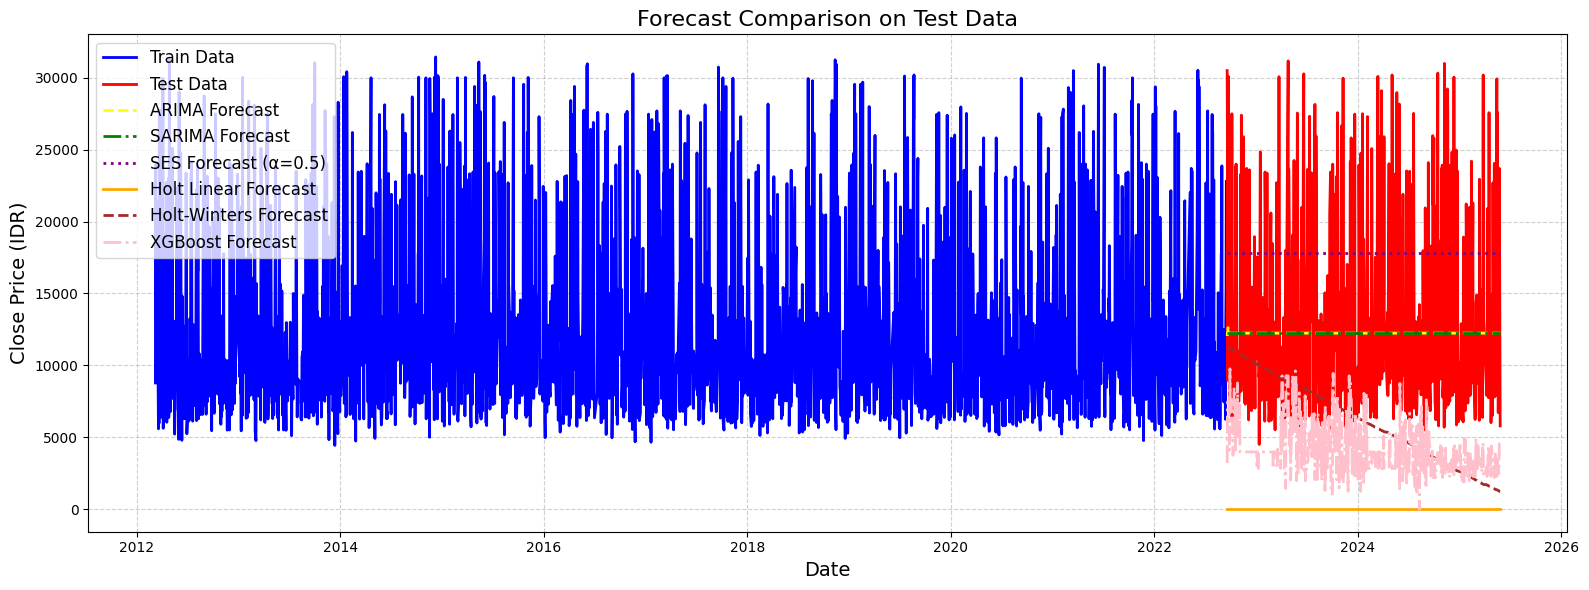

In [ ]:
# Forecast comparison
forecast_start_index = 2560  # Assuming that x[:2560] is the train data and x[2560:] is the test data

plt.figure(figsize=(16, 6))

# Plot train data (blue line)
plt.plot(x[:forecast_start_index], train, c='blue', label='Train Data', linewidth=2)

# Plot test data (red line)
plt.plot(x[forecast_start_index:], test, c='red', label='Test Data', linewidth=2)

# Plot each forecast model
plt.plot(x[forecast_start_index:], forecasts_arima, c='yellow', label='ARIMA Forecast', linestyle='--', linewidth=2)
plt.plot(x[forecast_start_index:], forecasts_sarima, c='green', label='SARIMA Forecast', linestyle='-.', linewidth=2)
plt.plot(x[forecast_start_index:], ses_forecasts[0.5], c='purple', label='SES Forecast (α=0.5)', linestyle=':', linewidth=2)
plt.plot(x[forecast_start_index:], holt_forecast, c='orange', label='Holt Linear Forecast', linestyle='-', linewidth=2)
plt.plot(x[forecast_start_index:], forecast_holtwinter, c='brown', label='Holt-Winters Forecast', linestyle='--', linewidth=2)
plt.plot(x[forecast_start_index:], forecast_xgb, c='pink', label='XGBoost Forecast', linestyle='-.', linewidth=2)
plt.title('Forecast Comparison on Test Data', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Close Price (IDR)', fontsize=14)
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


#### The chart compares the actual BBCA closing prices (blue) with forecasts from different models (red), including ARIMA, SARIMA, SES, Holt Linear, Holt-Winters, and XGBoost.
#### The forecast models' accuracy varies, with some showing better alignment with actual data than others, particularly during the periods of high volatility in 2020.